# Building Agents That Use Code

This notebook is part of the [Hugging Face Agents Course](https://www.hf.co/learn/agents-course), a free Course from beginner to expert, where you learn to build Agents.

![Agents course share](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/communication/share.png)

## Install dependencies and configure OpenAI

This notebook follows the same OpenAI setup as `retrieval_agents.ipynb`. Install `smolagents` with OpenAI support, then set your API key securely (never paste it into the notebook).


In [1]:
# Prefer the agents-course .venv kernel (Kernel -> Change Kernel -> Python 3 / agents-course).
# --no-cache-dir avoids corrupted pip cache warnings.
%pip install -q --no-cache-dir 'smolagents[openai]' gradio_client


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Set `OPENAI_API_KEY` in your environment or `.env` file. If it is missing, the next cell prompts for it securely with `getpass`.

Optionally set `OPENAI_MODEL` (defaults to `gpt-4o-mini`).

Later web-search examples use `WebSearchTool` with the Bing engine (more reliable than the default DuckDuckGo scraper for many environments), plus `VisitWebpageTool`.


In [2]:
import os
from getpass import getpass

from smolagents import OpenAIServerModel

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
model = OpenAIServerModel(model_id=OPENAI_MODEL, max_tokens=4096)

print(f"Using OpenAI model: {OPENAI_MODEL}")
print(f"OpenAI is configured: {bool(os.getenv('OPENAI_API_KEY'))}")

Using OpenAI model: gpt-4o-mini
OpenAI is configured: True


## The `@tool` Decorator  

### Generating a tool that retrieves the highest-rated catering

Let's imagine that Alfred has already decided on the menu for the party, but now he needs help preparing food for such a large number of guests. To do so, he would like to hire a catering service and needs to identify the highest-rated options available. Alfred can leverage a tool to search for the best catering services in his area.

Below is an example of how Alfred can use the `@tool` decorator to make this happen:

In [3]:
from smolagents import CodeAgent, tool

# Let's pretend we have a function that fetches the highest-rated catering services.
@tool
def catering_service_tool(query: str) -> str:
    """
    This tool returns the highest-rated catering service in Gotham City.

    Args:
        query: A search term for finding catering services.
    """
    # Example list of catering services and their ratings
    services = {
        "Gotham Catering Co.": 4.9,
        "Wayne Manor Catering": 4.8,
        "Gotham City Events": 4.7,
    }

    # Find the highest rated catering service (simulating search query filtering)
    best_service = max(services, key=services.get)

    return best_service


agent = CodeAgent(tools=[catering_service_tool], model=model)

# Run the agent to find the best catering service
result = agent.run(
    "Can you give me the name of the highest-rated catering service in Gotham City?"
)

print(result)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Can you give me the name of the highest-rated catering service in Gotham City?                                  │
│                                                                                                                 │
╰─ OpenAIModel - gpt-4o-mini ─────────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  highest_rated_catering_service = catering_service_tool(query="highest-rated catering service in Gotham City")    
  print(highest_rated_catering_service)                                                                            
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
Gotham Catering Co.

Out: None

[Step 1: Duration 2.29 seconds| Input tokens: 2,026 | Output tokens: 76]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Gotham Catering Co.")                                                                              
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Gotham Catering Co.

[Step 2: Duration 1.13 seconds| Input tokens: 4,220 | Output tokens: 126]

Gotham Catering Co.


## Defining a Tool as a Python Class  

### Generating a tool to generate ideas about the superhero-themed party

Alfred's party at the mansion is a **superhero-themed event**, but he needs some creative ideas to make it truly special. As a fantastic host, he wants to surprise the guests with a unique theme.

To do this, he can use an agent that generates superhero-themed party ideas based on a given category. This way, Alfred can find the perfect party theme to wow his guests.

In [4]:
from smolagents import CodeAgent, Tool

class SuperheroPartyThemeTool(Tool):
    name = "superhero_party_theme_generator"
    description = """
    This tool suggests creative superhero-themed party ideas based on a category.
    It returns a unique party theme idea."""

    inputs = {
        "category": {
            "type": "string",
            "description": "The type of superhero party (e.g., 'classic heroes', 'villain masquerade', 'futuristic Gotham').",
        }
    }

    output_type = "string"

    def forward(self, category: str):
        themes = {
            "classic heroes": "Justice League Gala: Guests come dressed as their favorite DC heroes with themed cocktails like 'The Kryptonite Punch'.",
            "villain masquerade": "Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.",
            "futuristic Gotham": "Neo-Gotham Night: A cyberpunk-style party inspired by Batman Beyond, with neon decorations and futuristic gadgets."
        }

        return themes.get(category.lower(), "Themed party idea not found. Try 'classic heroes', 'villain masquerade', or 'futuristic Gotham'.")

# Instantiate the tool
party_theme_tool = SuperheroPartyThemeTool()
agent = CodeAgent(tools=[party_theme_tool], model=model)

# Run the agent to generate a party theme idea
result = agent.run(
    "What would be a good superhero party idea for a 'villain masquerade' theme?"
)

print(result)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What would be a good superhero party idea for a 'villain masquerade' theme?                                     │
│                                                                                                                 │
╰─ OpenAIModel - gpt-4o-mini ─────────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  party_idea = superhero_party_theme_generator(category="villain masquerade")                                      
  print(party_idea)                                                                                                
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.

Out: None

[Step 1: Duration 2.21 seconds| Input tokens: 2,057 | Output tokens: 89]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.")      
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.

[Step 2: Duration 2.12 seconds| Input tokens: 4,301 | Output tokens: 176]

Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.


## Sharing a Tool to the Hub (optional)

Sharing your custom tool with the community is optional and still uses the Hugging Face Hub. Upload it with `push_to_hub()` if you have an `HF_TOKEN`.

For instance, Alfred can share his `SuperheroPartyThemeTool` like this:


In [5]:
# Optional: requires HF_TOKEN. Skip this cell if you are only using OpenAI locally.
# party_theme_tool.push_to_hub("YOUR_HF_USERNAME/superhero_party_theme_tool", token=os.getenv("HF_TOKEN"))
print("Skipping Hub upload by default. Uncomment the push_to_hub line if you want to share the tool.")

Skipping Hub upload by default. Uncomment the push_to_hub line if you want to share the tool.


## Generating images with the OpenAI API

The tool is named `image_generator` (so agent code like `image_generator(prompt)` works), but it calls **OpenAI Images** only — not Hugging Face.

Restart the kernel, run the OpenAI setup cell, then run the next cell. Optionally set `OPENAI_IMAGE_MODEL` (defaults to the speed-optimized `gpt-image-2.5-flare`) and `OPENAI_IMAGE_QUALITY` (`low`, `medium`, or `high`; defaults to `low`). The agent's code-execution timeout is raised because image generation can legitimately take longer than 30 seconds.

In [6]:
import base64
import os
import urllib.request
from pathlib import Path

from openai import OpenAI
from smolagents import CodeAgent, tool

OUTPUT_IMAGE = Path("generated_party_image.png")


@tool
def image_generator(prompt: str) -> str:
    """Generate an image with the OpenAI Images API (NOT Hugging Face) and save it locally.

    Args:
        prompt: A detailed text description of the image to generate.
    """
    if not os.getenv("OPENAI_API_KEY"):
        raise RuntimeError("OPENAI_API_KEY is not set. Run the OpenAI setup cell first.")

    client = OpenAI(
        api_key=os.environ["OPENAI_API_KEY"],
        timeout=90.0,
        max_retries=1,
    )
    image_model = os.getenv("OPENAI_IMAGE_MODEL", "gpt-image-2.5-flare")
    image_quality = os.getenv("OPENAI_IMAGE_QUALITY", "low")

    # Do not pass response_format — newer Image APIs reject it.
    result = client.images.generate(
        model=image_model,
        prompt=prompt,
        size="1024x1024",
        quality=image_quality,
        n=1,
    )
    item = result.data[0]
    if getattr(item, "b64_json", None):
        OUTPUT_IMAGE.write_bytes(base64.b64decode(item.b64_json))
    elif getattr(item, "url", None):
        urllib.request.urlretrieve(item.url, OUTPUT_IMAGE)
    else:
        raise RuntimeError(f"Unexpected image response: {item}")

    return f"Saved OpenAI image to {OUTPUT_IMAGE.resolve()}"


print(
    "image_generator backend: OpenAI",
    os.getenv("OPENAI_IMAGE_MODEL", "gpt-image-2.5-flare"),
    "quality=" + os.getenv("OPENAI_IMAGE_QUALITY", "low"),
)

agent = CodeAgent(
    tools=[image_generator],
    model=model,
    max_steps=6,
    executor_kwargs={"timeout_seconds": 120},
)

result = agent.run(
    "Generate an image of a luxurious superhero-themed party at Wayne Manor with made-up superheroes."
)
print(result)
print("Image path:", OUTPUT_IMAGE.resolve() if OUTPUT_IMAGE.exists() else "(not created yet)")

image_generator backend: OpenAI gpt-image-2.5-flare quality=low


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Generate an image of a luxurious superhero-themed party at Wayne Manor with made-up superheroes.                │
│                                                                                                                 │
╰─ OpenAIModel - gpt-4o-mini ─────────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  image_prompt = "A luxurious superhero-themed party at Wayne Manor. The scene is opulent with elegant             
  decorations, chandeliers, and a grand dining area. Various made-up superheroes are mingling, dressed in          
  extravagant costumes, including a hero with a shimmering green cape, another with a suit inspired by a majestic  
  lion, and a heroine with armor adorned with stars. The atmosphere is festive, with guests enjoying gourmet food  
  and drinks, and a beautiful garden view through large windows."                                                  
  image = image_generator(image_prompt)                                                                            
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Out: Saved OpenAI image to 
/Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png

...

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("/Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png")     
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: /Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png

[Step 2: Duration 1.20 seconds| Input tokens: 4,436 | Output tokens: 246]

/Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png
Image path: /Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png


## Improve a prompt, then generate

Same OpenAI-backed `image_generator` tool — refine Alfred's brief, then generate.

In [9]:
agent = CodeAgent(
    tools=[image_generator],
    model=model,
    max_steps=8,
    executor_kwargs={"timeout_seconds": 120},
)

result = agent.run(
    "Improve this prompt for image generation, then call image_generator with the improved prompt. "
    "User prompt: A grand superhero-themed party at Wayne Manor, with Alfred overseeing a luxurious gala."
)
print(result)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Improve this prompt for image generation, then call image_generator with the improved prompt. User prompt: A    │
│ grand superhero-themed party at Wayne Manor, with Alfred overseeing a luxurious gala.                           │
│                                                                                                                 │
╰─ OpenAIModel - gpt-4o-mini ─────────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  improved_prompt = "An extravagant superhero-themed party at Wayne Manor, featuring stunning decorations with     
  superhero emblems, elegantly dressed guests mingling, and Alfred, the butler, gracefully overseeing the          
  luxurious gala, complete with a grand chandelier illuminating the scene."                                        
  image_path = image_generator(improved_prompt)                                                                    
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Out: Saved OpenAI image to 
/Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png

[Step 1: Duration 15.43 seconds| Input tokens: 2,054 | Output tokens: 198]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("The image has been generated and saved at                                                          
  /Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png.")                  
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: The image has been generated and saved at 
/Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png.

[Step 2: Duration 1.55 seconds| Input tokens: 4,446 | Output tokens: 269]

The image has been generated and saved at /Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png.


In [10]:
# Display helper markdown moved below — this cell intentionally left as a quick sanity check.
print("OpenAI image_generator is defined:" , "image_generator" in globals())
print("Expected output file:", OUTPUT_IMAGE.resolve())

OpenAI image_generator is defined: True
Expected output file: /Users/hongtang/Documents/agents-course/notebooks/unit2/smolagents/generated_party_image.png


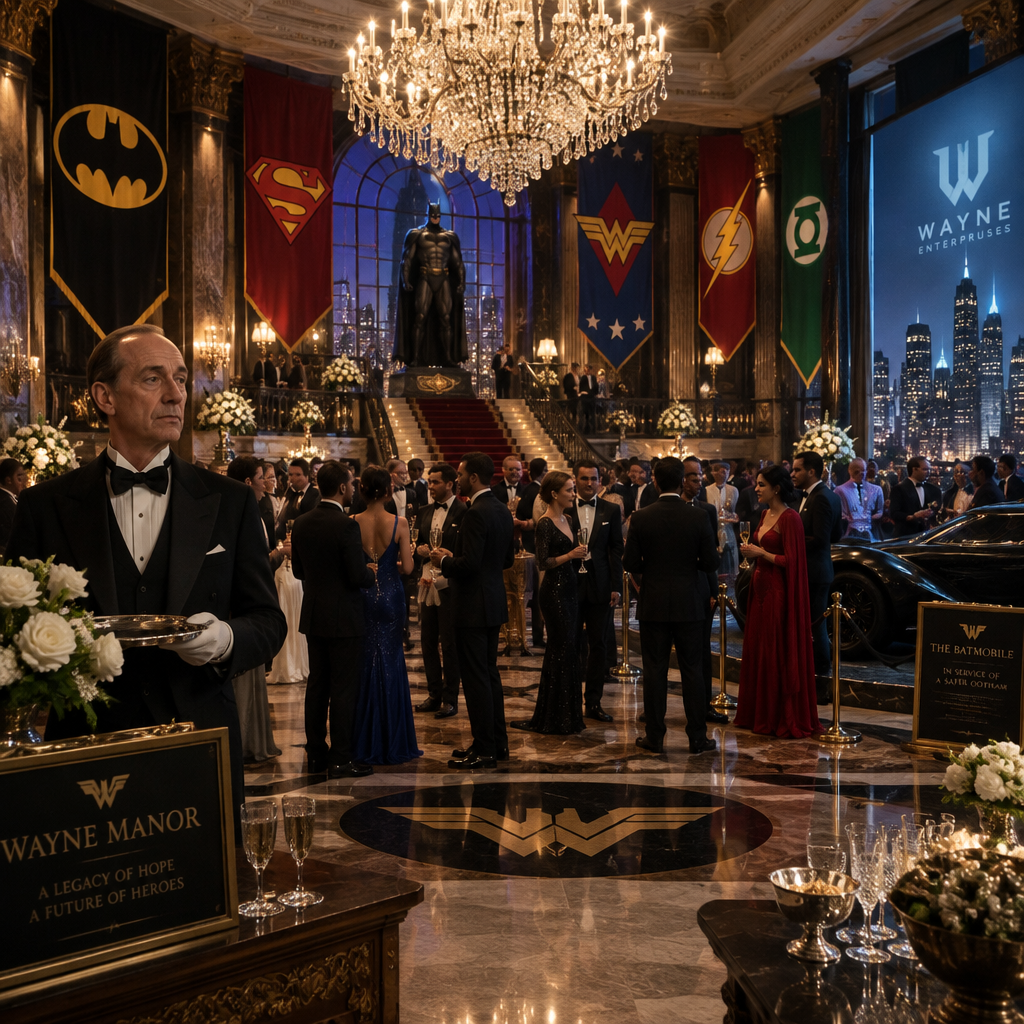

In [11]:
from PIL import Image as PILImage

assert OUTPUT_IMAGE.exists(), f"Missing {OUTPUT_IMAGE.resolve()} — re-run the OpenAI image cell above."
img = PILImage.open(OUTPUT_IMAGE)
img

## Web Search Tool (Bing)

Instead of SerpAPI, this notebook uses the same reliable public search pattern as `retrieval_agents.ipynb`: `WebSearchTool` with the Bing engine, plus `VisitWebpageTool` to open promising pages.

No separate SerpAPI or Serper credential is required. The public search backend may rate-limit large runs.


In [12]:
# No extra packages needed beyond the setup cell.
print("Ready to build the Bing web-search agent.")

Ready to build the Bing web-search agent.


In [13]:
from smolagents import CodeAgent, VisitWebpageTool, WebSearchTool

# Prefer Bing for more reliable public web search (same pattern as retrieval_agents.ipynb)
search_tool = WebSearchTool(max_results=10, engine="bing")
visit_tool = VisitWebpageTool()

print("Web search tools ready:", search_tool.name, visit_tool.name)

Web search tools ready: web_search visit_webpage


In [14]:
agent = CodeAgent(
    tools=[search_tool, visit_tool],
    model=model,
    max_steps=10,
)

agent.run(
    "Search for luxury entertainment ideas for a superhero-themed event, such as live performances and interactive experiences."
)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Search for luxury entertainment ideas for a superhero-themed event, such as live performances and interactive   │
│ experiences.                                                                                                    │
│                                                                                                                 │
╰─ OpenAIModel - gpt-4o-mini ─────────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  luxury_entertainment_ideas = web_search("luxury entertainment ideas superhero-themed event live performances     
  interactive experiences")                                                                                        
  print(luxury_entertainment_ideas)                                                                                
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
## Search Results

[LUXURY Definition & Meaning - Merriam-Webster](https://www.merriam-webster.com/dictionary/luxury)
The meaning of LUXURY is a condition of abundance or great ease and comfort : sumptuous environment. How to use 
luxury in a sentence.

[LUXURY | English meaning - Cambridge Dictionary](https://dictionary.cambridge.org/dictionary/english/luxury)
LUXURY definition: 1. great comfort, especially as provided by expensive and beautiful things: 2. something 
expensive…. Learn more.

[Luxury - Wikipedia](https://en.wikipedia.org/wiki/Luxury)
This disambiguation page lists articles associated with the title Luxury. If an internal link incorrectly led you 
here, you may wish to change the link to point directly to the intended article.

[Luxury - Definition, Meaning & Synonyms | Vocabulary.com](https://www.vocabulary.com/dictionary/luxury)
A luxury is something that is pleasant to have or experience, but it is not necessary. For example, eating in a 
restaurant is a luxury — you can always cook and eat at home.

[Luxury goods - Wikipedia](https://en.wikipedia.org/wiki/Luxury_goods)
In economics, a luxury good (or upmarket good) is a product or item or service for which demand increases more than
what is proportional as income rises, so that expenditures on the good become a more significant proportion of 
overall spending.

[LUXURY | definition in the Cambridge English 
Dictionary](https://dictionary.cambridge.org/us/dictionary/english/luxury)
LUXURY meaning: 1. great comfort, especially as provided by expensive and beautiful things: 2. something 
expensive…. Learn more.

[Luxury Fashion, Designer Wear, Beauty & Lifestyle Shopping Online ...](https://luxury.tatacliq.com/)
Shop curated designer fashion, accessories and lifestyle picks for men & women. Explore top global luxury brands in
watches, bags, footwear and apparel on Tata CLiQ Luxury

[TOP 100 Best Luxury Brands of the World - 
WLCC](https://worldluxurychamber.com/top-100-best-luxury-brands-of-the-world-celebrated-in-inaugural-world-luxury-d
ay-festivities/)
The TOP 100 by Luxury Lifestyle Awards honors the world’s most distinguished luxury brands, businesses, and 
individuals who exemplify excellence, creativity, and ethical leadership across the global luxury industry.

[Luxury | Definition & Examples | Britannica Money](https://www.britannica.com/money/luxury)
luxury, word that implies a relatively large consumption of wealth for nonessential pleasures. There is, however, 
no absolute definition of luxury, for the conception is relative to both time and person.

[Luxury (@luxury) • Instagram photos and videos](https://www.instagram.com/luxury/)
5M Followers, 21 Following, 1,547 Posts - Luxury (@luxury) on Instagram: "The world’s leading luxury media platform
Partnerships: 📩 info@igluxury.com"

Out: None

[Step 1: Duration 2.28 seconds| Input tokens: 2,093 | Output tokens: 81]

...

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 8 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  entertainment_suggestions = [                                                                                    
      "Character appearances with professional cosplayers in superhero costumes for photo opportunities.",         
      "Live stunt performances simulating superhero actions.",                                                     
      "Interactive gaming setups utilizing virtual reality themed around superheroes.",                            
      "Themed escape rooms designed with superhero narratives.",                                                   
      "Superhero-themed scavenger hunts throughout the venue.",                                                    
      "Dance or musical performances featuring superhero-themed soundtracks.",                                     
      "Catering that includes superhero-inspired treats or mocktail bars."                                         
  ]                                                                                                                
  final_answer(entertainment_suggestions)                                                                          
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: ['Character appearances with professional cosplayers in superhero costumes for photo opportunities.',
'Live stunt performances simulating superhero actions.', 'Interactive gaming setups utilizing virtual reality 
themed around superheroes.', 'Themed escape rooms designed with superhero narratives.', 'Superhero-themed scavenger
hunts throughout the venue.', 'Dance or musical performances featuring superhero-themed soundtracks.', 'Catering 
that includes superhero-inspired treats or mocktail bars.']

[Step 8: Duration 2.90 seconds| Input tokens: 38,433 | Output tokens: 1,004]

['Character appearances with professional cosplayers in superhero costumes for photo opportunities.',
 'Live stunt performances simulating superhero actions.',
 'Interactive gaming setups utilizing virtual reality themed around superheroes.',
 'Themed escape rooms designed with superhero narratives.',
 'Superhero-themed scavenger hunts throughout the venue.',
 'Dance or musical performances featuring superhero-themed soundtracks.',
 'Catering that includes superhero-inspired treats or mocktail bars.']

With this setup, Alfred can quickly discover luxurious entertainment options, ensuring Gotham's elite guests have an unforgettable experience. This tool helps him curate the perfect superhero-themed event experience for Wayne Manor!
